# Ejercicio 5 — Calidad del aire

Análisis de los datos originales del centro. Se eliminan duplicados exactos; no se imputan valores ausentes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargamos los datos y eliminamos duplicados exactos.
df = pd.read_csv('centro_fp_monitorizacion.csv')
print('Dimensiones originales:', df.shape)
print('Duplicados:', df.duplicated().sum())
print('Ausentes por columna:', df.isna().sum())
df = df.drop_duplicates().copy()


Dimensiones originales: (363, 12)
Duplicados: 3
Ausentes por columna: fecha                0
dia                  0
hora                 0
aula                 0
alumnos              0
temperatura_c        0
humedad_pct          0
co2_ppm              6
consumo_kwh          0
dispositivos_wifi    0
desconexiones        0
latencia_ms          0
dtype: int64


In [2]:
# Excluimos únicamente las lecturas sin CO2 para este análisis.
aire = df.dropna(subset=['co2_ppm']).copy()
aire['alerta'] = aire['co2_ppm'] > 1000
aire['grave'] = aire['co2_ppm'] > 1200
resumen = aire.groupby('aula').agg(media=('co2_ppm','mean'), lecturas=('co2_ppm','count'), alertas=('alerta','sum'), graves=('grave','sum'))
resumen['porcentaje_alertas'] = resumen['alertas'] / resumen['lecturas'] * 100
display(resumen.round(2))
alertas = aire[aire['alerta']]
display(alertas)
alertas.to_json('alertas_aire.json', orient='records', indent=4, force_ascii=False)
display(aire.groupby('hora')['alerta'].agg(['sum','mean','count']))
print(aire[['alumnos','co2_ppm']].corr())
print(aire[aire['alumnos']>0][['alumnos','co2_ppm']].corr())


,media,lecturas,alertas,graves,porcentaje_alertas
aula,,,,,
A,737.62,118,8,0,6.78
B,902.03,117,42,38,35.90
C,767.66,119,13,0,10.92


,fecha,dia,hora,aula,alumnos,temperatura_c,humedad_pct,co2_ppm,consumo_kwh,dispositivos_wifi,desconexiones,latencia_ms,alerta,grave
16,2026-10-01,1,12,B,25,25.2,44.7,1424.0,3.97,32,0,64.3,True,True
18,2026-10-01,1,14,B,15,24.2,45.5,1320.0,2.55,19,0,46.7,True,True
19,2026-10-01,1,15,B,24,22.8,62.5,1406.0,3.71,28,0,45.2,True,True
52,2026-10-02,2,12,B,16,22.9,62.1,1283.0,2.56,16,1,58.5,True,True
53,2026-10-02,2,13,B,17,26.0,40.0,1348.0,3.53,20,2,76.4,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
340,2026-10-10,10,12,B,26,22.8,47.9,1321.0,3.79,30,1,61.2,True,True
341,2026-10-10,10,13,B,26,26.1,39.9,1544.0,4.44,27,1,70.3,True,True
342,2026-10-10,10,14,B,29,25.7,59.9,1388.0,4.75,36,2,86.7,True,True
343,2026-10-10,10,15,B,19,25.7,51.9,1227.0,3.49,25,1,60.8,True,True


,sum,mean,count
hora,,,
8,3,0.100000,30
9,2,0.066667,30
10,4,0.137931,29
11,1,0.034483,29
12,14,0.482759,29
13,10,0.357143,28
14,12,0.413793,29
15,13,0.433333,30
16,4,0.133333,30


          alumnos   co2_ppm
alumnos  1.000000  0.810811
co2_ppm  0.810811  1.000000
          alumnos   co2_ppm
alumnos  1.000000  0.405924
co2_ppm  0.405924  1.000000


<Figure size 800x400 with 0 Axes>

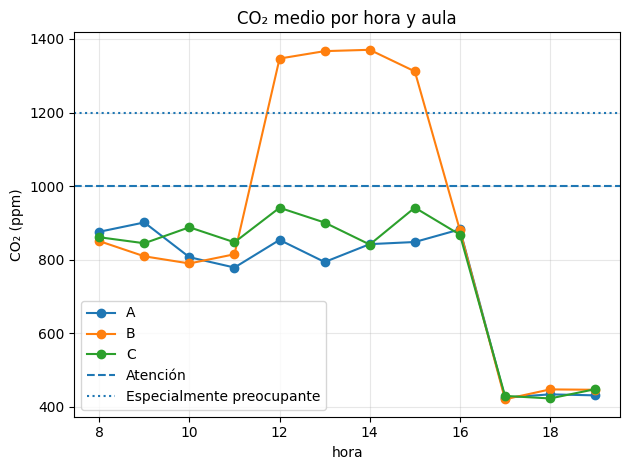

In [3]:
plt.figure(figsize=(8, 4))
# Comparamos el nivel medio por hora y aula.
aire.groupby(['hora','aula'])['co2_ppm'].mean().unstack().plot(marker='o')
plt.axhline(1000, linestyle='--', label='Atención')
plt.axhline(1200, linestyle=':', label='Especialmente preocupante')
plt.title('CO₂ medio por hora y aula')
plt.ylabel('CO₂ (ppm)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('grafica_1.jpg', dpi=150)
plt.show()
plt.close()

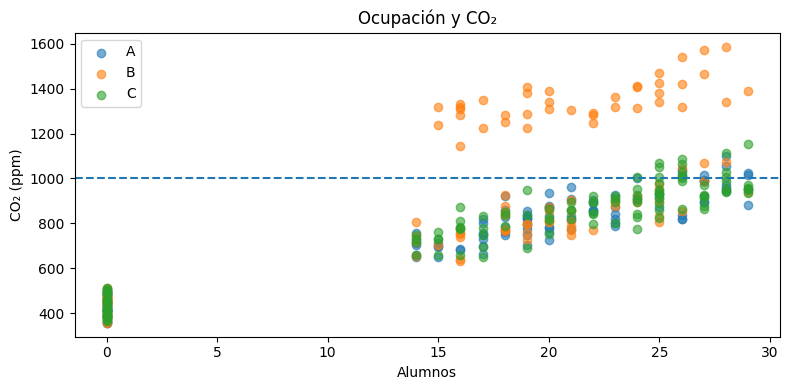

In [4]:
plt.figure(figsize=(8, 4))
# La dispersión permite comparar lecturas con ocupación similar.
for aula in aire['aula'].unique():
    datos = aire[aire['aula']==aula]
    plt.scatter(datos['alumnos'], datos['co2_ppm'], label=aula, alpha=0.6)
plt.axhline(1000, linestyle='--')
plt.xlabel('Alumnos')
plt.ylabel('CO₂ (ppm)')
plt.title('Ocupación y CO₂')
plt.legend()
plt.tight_layout()
plt.savefig('grafica_2.jpg', dpi=150)
plt.show()
plt.close()

## Conclusiones

1. **Prioridad:** B, con media de 902,03 ppm y 42 alertas de 117 lecturas válidas (35,90 %), frente a 8 en A y 13 en C. Las 38 lecturas superiores a 1200 ppm pertenecen a B.
2. **Horario:** 49 de las 63 alertas se concentran entre las 12 y las 15 horas inclusive. La gráfica temporal permite localizar esa franja.
3. **Ocupación:** correlación de Pearson de 0,81 en conjunto y 0,41 solo con alumnos. Todas las alertas tienen alumnos, pero la ocupación no explica por sí sola las diferencias entre aulas. La dispersión permite comprobarlo.
4. **Calidad:** se eliminan tres duplicados exactos y se excluyen seis CO₂ ausentes, sin sustituirlos por cero. Quedan 354 lecturas válidas; los porcentajes usan sus denominadores por aula. Los ausentes podrían sesgar los resultados.
5. **Acciones:** revisar ventilación y sensores de B, especialmente de 12 a 15; registrar apertura de ventanas y caudal de aire. Repetir mediciones con ocupaciones comparables y comprobar si disminuye el porcentaje de alertas. Los umbrales son criterios del ejercicio, no diagnósticos.